# TRUSTSR Lab 01.6 — Randomized Synthetic Recovery Evaluation

**Status:** Synthetic simulation / research prototype  
**Version:** 0.1.0  
**Purpose:** Fix a metric-design flaw in Lab 01.5 and test strategies across many generated dependency graphs.

## Why this lab is needed
Lab 01.5 scored full rollback as though restored checkpoint states were still contaminated, while also describing them as restored. That conflates **quarantine** with **recovery**. This lab separates:
- **Contamination remaining after response** (false negatives among affected states),
- **Quarantine cost** (states held unavailable),
- **Valid post-checkpoint work lost** under rollback,
- **Unchanged unaffected states preserved**.

## Strategies
1. **Checkpoint rollback:** Assumes a trusted checkpoint exists. All post-checkpoint state versions are discarded and checkpoint versions are restored. In this simplified model, contamination remaining after rollback is zero; valid post-checkpoint work loss is counted separately.
2. **Observed reachability quarantine:** Quarantines affected states reachable from the poison source in the observed graph. Missing dependency edges can hide affected states.
3. **Reachability + declared-edge uncertainty quarantine:** In addition to reachable states, quarantines the dependent endpoint and its observed descendants for every missing edge explicitly supplied to the policy. It does not detect missing edges itself.

## Experimental design
Generate randomized directed acyclic graphs (DAGs), inject a poison source, remove a subset of edges, and compare the strategies against unchanged synthetic ground truth. Use a fixed random seed for reproducibility. This is a simulation study, not a real-agent experiment.

**Critical limitation:** The uncertainty policy is given the missing-edge list by the simulation controller. Its results are conditional on receiving those signals and do not measure missing-edge detection performance. All outputs are synthetic and must not be represented as real-world evidence.

## 1. Install and import dependencies

In [1]:
%pip -q install networkx pandas matplotlib numpy

In [2]:
import sys, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

SEED = 20261010
rng = np.random.default_rng(SEED)
N_TRIALS = 300
N_NODES = 24
EDGE_PROBABILITY = 0.13
EDGE_REMOVAL_PROBABILITY = 0.15

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NetworkX:", nx.__version__, "| Pandas:", pd.__version__, "| NumPy:", np.__version__)
print("Seed:", SEED, "| Trials:", N_TRIALS, "| Nodes/graph:", N_NODES)
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence type: synthetic simulation only")

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
NetworkX: 3.6.1 | Pandas: 3.0.2 | NumPy: 2.4.4
Seed: 20261010 | Trials: 300 | Nodes/graph: 24
Execution UTC: 2026-10-11T10:26:26.679283+00:00
Evidence type: synthetic simulation only


## 2. Define graph generation and policy functions

In [3]:
def generate_trial_graph(rng, n_nodes=N_NODES, edge_p=EDGE_PROBABILITY):
    # Node 0 is the poison source. Edges only go from lower to higher IDs, ensuring a DAG.
    G = nx.DiGraph()
    G.add_nodes_from(range(n_nodes))
    for u in range(n_nodes):
        for v in range(u + 1, n_nodes):
            if rng.random() < edge_p:
                G.add_edge(u, v)
    # Ensure at least one downstream branch from source for informative trials.
    if G.out_degree(0) == 0:
        G.add_edge(0, int(rng.integers(1, n_nodes)))
    return G

def remove_random_edges(G_truth, rng, removal_p=EDGE_REMOVAL_PROBABILITY):
    G_obs = G_truth.copy()
    removed = []
    for edge in list(G_truth.edges()):
        if rng.random() < removal_p:
            G_obs.remove_edge(*edge)
            removed.append(edge)
    return G_obs, removed

def observed_reachability(G_obs, source=0):
    return set(nx.descendants(G_obs, source))

def uncertainty_quarantine(G_obs, removed_edges, source=0):
    quarantine = observed_reachability(G_obs, source)
    unknown = set()
    for _u, v in removed_edges:
        unknown.add(v)
        unknown.update(nx.descendants(G_obs, v))
    unknown -= quarantine
    unknown.discard(source)
    return quarantine | unknown, unknown

def evaluate_trial(G_truth, G_obs, removed_edges, source=0):
    affected = set(nx.descendants(G_truth, source))
    unaffected = set(G_truth.nodes()) - affected - {source}
    baseline_q = observed_reachability(G_obs, source)
    conservative_q, unknown = uncertainty_quarantine(G_obs, removed_edges, source)

    # State dispositions are modeled explicitly, rather than treating restored states as quarantined.
    # Rollback: all post-checkpoint versions are discarded; checkpoint versions are restored.
    # Affected descendants are therefore not counted as contaminated after rollback in this idealized model.
    strategies = [
        {
            "strategy": "Checkpoint rollback (idealized)",
            "remaining_affected": set(),
            "quarantined": set(),
            "unknown": set(),
            "valid_work_lost": len(unaffected),
            "unaffected_preserved": 0,
            "rollback_performed": True,
        },
        {
            "strategy": "Observed reachability quarantine",
            "remaining_affected": affected - baseline_q,
            "quarantined": baseline_q,
            "unknown": set(),
            "valid_work_lost": 0,
            "unaffected_preserved": len(unaffected - baseline_q),
            "rollback_performed": False,
        },
        {
            "strategy": "Reachability + declared-edge uncertainty",
            "remaining_affected": affected - conservative_q,
            "quarantined": conservative_q,
            "unknown": unknown,
            "valid_work_lost": 0,
            "unaffected_preserved": len(unaffected - conservative_q),
            "rollback_performed": False,
        },
    ]

    rows = []
    for s in strategies:
        affected_n = len(affected)
        fn = len(s["remaining_affected"])
        unaffected_n = len(unaffected)
        rows.append({
            "strategy": s["strategy"],
            "affected_count": affected_n,
            "false_negative_count": fn,
            "false_negative_rate": fn / affected_n if affected_n else np.nan,
            "quarantined_count": len(s["quarantined"]),
            "unaffected_over_quarantined_count": len(s["quarantined"] & unaffected),
            "unaffected_preserved_count": s["unaffected_preserved"],
            "unaffected_preservation_rate": s["unaffected_preserved"] / unaffected_n if unaffected_n else np.nan,
            "valid_work_lost_count": s["valid_work_lost"],
            "unknown_unverified_count": len(s["unknown"]),
            "removed_edge_count": len(removed_edges),
            "truth_edge_count": G_truth.number_of_edges(),
            "observed_edge_count": G_obs.number_of_edges(),
        })
    return rows, affected, unaffected, baseline_q, conservative_q, unknown

print("Graph generator and evaluation functions defined.")

Graph generator and evaluation functions defined.


## 3. Run randomized trials

In [4]:
all_rows = []
trial_summaries = []
for trial_id in range(N_TRIALS):
    G_truth = generate_trial_graph(rng)
    G_obs, removed_edges = remove_random_edges(G_truth, rng)
    # Skip degenerate graphs with no poison descendants; record count for transparency.
    affected = set(nx.descendants(G_truth, 0))
    if not affected:
        continue
    rows, affected, unaffected, baseline_q, conservative_q, unknown = evaluate_trial(
        G_truth, G_obs, removed_edges, source=0
    )
    for row in rows:
        row["trial_id"] = trial_id
        all_rows.append(row)
    trial_summaries.append({
        "trial_id": trial_id,
        "nodes": G_truth.number_of_nodes(),
        "truth_edges": G_truth.number_of_edges(),
        "removed_edges": len(removed_edges),
        "affected_count": len(affected),
        "unaffected_count": len(unaffected),
        "baseline_false_negatives": len(affected - baseline_q),
        "conservative_false_negatives": len(affected - conservative_q),
        "conservative_unknown_count": len(unknown),
    })

results_df = pd.DataFrame(all_rows)
trials_df = pd.DataFrame(trial_summaries)
print("Requested trials:", N_TRIALS)
print("Evaluated non-degenerate trials:", trials_df["trial_id"].nunique())
print("Strategy rows:", len(results_df))
display(results_df.head())
display(trials_df.describe(include="all"))

Requested trials: 300
Evaluated non-degenerate trials: 300
Strategy rows: 900


                                   strategy  affected_count  false_negative_count  false_negative_rate  quarantined_count  unaffected_over_quarantined_count  unaffected_preserved_count  \
0           Checkpoint rollback (idealized)              14                     0             0.000000                  0                                  0                           0   
1          Observed reachability quarantine              14                     6             0.428571                  8                                  0                           9   
2  Reachability + declared-edge uncertainty              14                     0             0.000000                 14                                  0                           9   
3           Checkpoint rollback (idealized)               4                     0             0.000000                  0                                  0                           0   
4          Observed reachability quarantine               4 

         trial_id  nodes  truth_edges  removed_edges  affected_count  unaffected_count  baseline_false_negatives  conservative_false_negatives  conservative_unknown_count
count  300.000000  300.0   300.000000     300.000000      300.000000        300.000000                300.000000                         300.0                  300.000000
mean   149.500000   24.0    35.726667       5.546667        8.280000         14.720000                  1.660000                           0.0                    4.896667
std     86.746758    0.0     5.570943       2.223579        4.839387          4.839387                  2.327184                           0.0                    3.439781
min      0.000000   24.0    20.000000       0.000000        1.000000          3.000000                  0.000000                           0.0                    0.000000
25%     74.750000   24.0    32.000000       4.000000        4.000000         11.000000                  0.000000                           0.0   

## 4. Aggregate measured synthetic outcomes

In [5]:
summary = results_df.groupby("strategy", as_index=False).agg(
    trial_rows=("trial_id", "count"),
    mean_false_negative_rate=("false_negative_rate", "mean"),
    median_false_negative_rate=("false_negative_rate", "median"),
    mean_quarantined_states=("quarantined_count", "mean"),
    mean_unaffected_over_quarantined=("unaffected_over_quarantined_count", "mean"),
    mean_unaffected_preservation_rate=("unaffected_preservation_rate", "mean"),
    mean_valid_work_lost=("valid_work_lost_count", "mean"),
    mean_unknown_unverified=("unknown_unverified_count", "mean"),
)
display(summary)
print("These are results from this seeded synthetic simulation only.")

                                   strategy  trial_rows  mean_false_negative_rate  median_false_negative_rate  mean_quarantined_states  mean_unaffected_over_quarantined  \
0           Checkpoint rollback (idealized)         300                  0.000000                         0.0                 0.000000                          0.000000   
1          Observed reachability quarantine         300                  0.215664                         0.1                 6.620000                          0.000000   
2  Reachability + declared-edge uncertainty         300                  0.000000                         0.0                11.516667                          3.236667   

   mean_unaffected_preservation_rate  mean_valid_work_lost  mean_unknown_unverified  
0                           0.000000                 14.72                 0.000000  
1                           1.000000                  0.00                 0.000000  
2                           0.806359                 

These are results from this seeded synthetic simulation only.


## 5. Plot false-negative rates across strategies

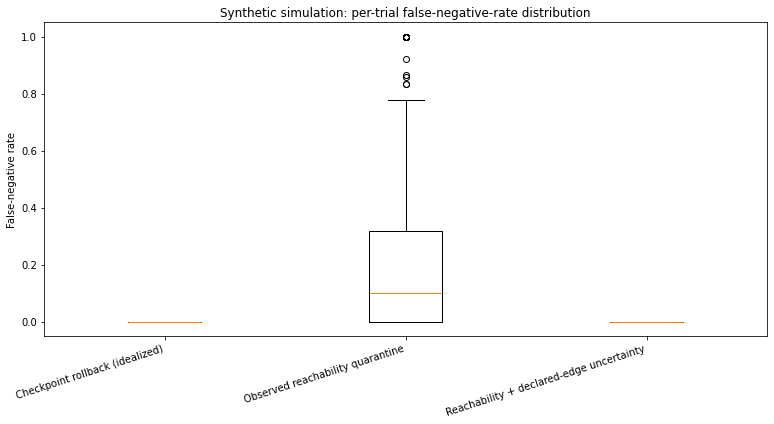

In [6]:
plot_df = results_df.groupby("strategy")["false_negative_rate"].apply(lambda s: s.dropna()).reset_index()
plt.figure(figsize=(11, 6))
data = [results_df.loc[results_df["strategy"] == name, "false_negative_rate"].dropna().values
        for name in results_df["strategy"].drop_duplicates()]
labels = list(results_df["strategy"].drop_duplicates())
plt.boxplot(data, tick_labels=labels)
plt.ylabel("False-negative rate")
plt.title("Synthetic simulation: per-trial false-negative-rate distribution")
plt.xticks(rotation=18, ha="right")
plt.tight_layout()
plt.show()

## 6. Plot quarantine cost and valid-work loss

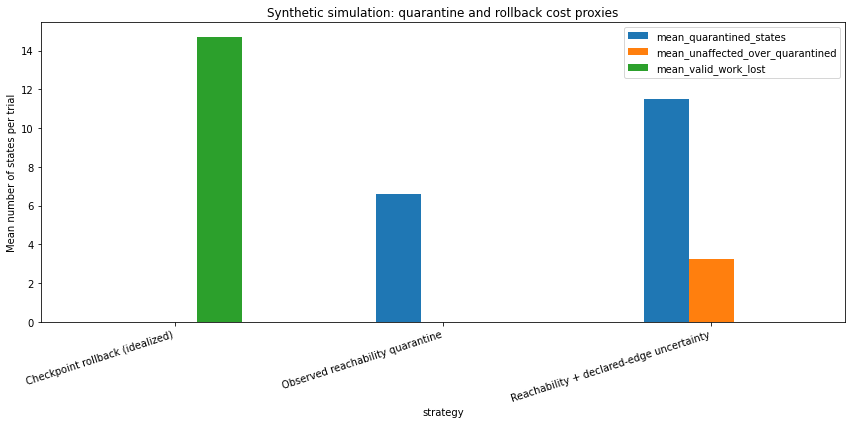

In [7]:
plot_cost = summary.set_index("strategy")[[
    "mean_quarantined_states", "mean_unaffected_over_quarantined", "mean_valid_work_lost"
]]
ax = plot_cost.plot(kind="bar", figsize=(12, 6))
ax.set_ylabel("Mean number of states per trial")
ax.set_title("Synthetic simulation: quarantine and rollback cost proxies")
plt.xticks(rotation=18, ha="right")
plt.tight_layout()
plt.show()

## 7. Analyze worst cases

In [8]:
worst = trials_df.sort_values(
    ["conservative_false_negatives", "removed_edges"], ascending=[False, False]
).head(10)
display(worst)
print("Worst-case table ranks trials by conservative-policy false negatives, then removed-edge count.")
print("A low false-negative count must be interpreted alongside quarantine overhead and the supplied-edge-signal assumption.")

     trial_id  nodes  truth_edges  removed_edges  affected_count  unaffected_count  baseline_false_negatives  conservative_false_negatives  conservative_unknown_count
105       105     24           45             13              10                13                         4                             0                           7
234       234     24           34             13               8                15                         5                             0                          10
249       249     24           46             11               9                14                         1                             0                           3
5           5     24           38             10              18                 5                         6                             0                           6
44         44     24           42             10               6                17                         5                             0                          1

Worst-case table ranks trials by conservative-policy false negatives, then removed-edge count.
A low false-negative count must be interpreted alongside quarantine overhead and the supplied-edge-signal assumption.


## 8. Assertions and consistency checks

In [9]:
assert len(results_df) == len(trials_df) * 3
assert set(results_df["strategy"].unique()) == {
    "Checkpoint rollback (idealized)",
    "Observed reachability quarantine",
    "Reachability + declared-edge uncertainty",
}
assert results_df["false_negative_count"].ge(0).all()
assert results_df["quarantined_count"].ge(0).all()
assert results_df["false_negative_rate"].dropna().between(0, 1).all()
assert results_df["unaffected_preservation_rate"].dropna().between(0, 1).all()

rollback_rows = results_df[results_df["strategy"] == "Checkpoint rollback (idealized)"]
assert (rollback_rows["false_negative_count"] == 0).all()
assert (rollback_rows["valid_work_lost_count"] >= 0).all()

# The uncertainty policy should never quarantine fewer states than reachability alone,
# because it adds a set of states to the baseline.
wide = results_df.pivot(index="trial_id", columns="strategy", values="quarantined_count")
assert (
    wide["Reachability + declared-edge uncertainty"] >=
    wide["Observed reachability quarantine"]
).all()

print("PASS: each evaluated trial has exactly three strategy rows.")
print("PASS: rates are bounded and counts are non-negative.")
print("PASS: idealized rollback has zero residual contamination by model definition; work loss is separate.")
print("PASS: uncertainty policy quarantine set is never smaller than baseline reachability.")
print("All Lab 01.6 assertions passed.")

PASS: each evaluated trial has exactly three strategy rows.
PASS: rates are bounded and counts are non-negative.
PASS: idealized rollback has zero residual contamination by model definition; work loss is separate.
PASS: uncertainty policy quarantine set is never smaller than baseline reachability.
All Lab 01.6 assertions passed.


## 9. Export CSV artifacts

In [10]:
results_df.to_csv("trustsr_lab01_6_trial_level_results.csv", index=False)
trials_df.to_csv("trustsr_lab01_6_trial_graph_summary.csv", index=False)
summary.to_csv("trustsr_lab01_6_strategy_aggregate_summary.csv", index=False)
worst.to_csv("trustsr_lab01_6_worst_case_trials.csv", index=False)
print("Generated files:")
print("- trustsr_lab01_6_trial_level_results.csv")
print("- trustsr_lab01_6_trial_graph_summary.csv")
print("- trustsr_lab01_6_strategy_aggregate_summary.csv")
print("- trustsr_lab01_6_worst_case_trials.csv")

Generated files:
- trustsr_lab01_6_trial_level_results.csv
- trustsr_lab01_6_trial_graph_summary.csv
- trustsr_lab01_6_strategy_aggregate_summary.csv
- trustsr_lab01_6_worst_case_trials.csv


## 10. Interpretation and limitations

1. **Synthetic only:** No live agent, real memory store, production dependency graph, or real incident logs were evaluated.
2. **Idealized rollback:** The checkpoint is assumed trusted and complete. Valid-work loss is a proxy based on unaffected post-checkpoint states; the simulation does not model timestamps or real user-visible side effects.
3. **Oracle-like missing-edge signal:** The conservative policy receives the exact removed-edge list. This does not evaluate missing-edge discovery.
4. **Graph model:** Nodes are integer IDs and edges only move from lower to higher IDs to ensure a DAG. This is not a validated model of real agent workflows.
5. **No causal proof:** Graph reachability is a simplified dependency heuristic. It does not establish that every reachable state is actually contaminated or that every real dependency is represented.
6. **No formal guarantees:** Passing assertions validates code invariants in this simulation, not soundness or completeness of TRUSTSR.

### Reporting rule
Report the seed, trial count, graph-generation parameters, exclusions, aggregate metrics, and limitations together. Do not use these synthetic results as evidence of real-world effectiveness or to substantiate unsupported numerical claims in the monograph.